# RSA between ResNet-50 and EEG: a demo on synthetic data

The same six steps as `demo_things_eeg.ipynb`, but on data we generate ourselves, so nothing needs to be downloaded except the model weights (about 100 MB, the first time).

- The **images** are synthetic: stripes with a known orientation, spatial frequency, colour and contrast, plus a bright blob of known position and size.
- The **EEG** is synthetic too, with a signal planted on purpose: between 100 and 400 ms after the image, the electrodes at the back of the head respond to these image properties. Everything else is noise.
- The **model** is the real thing: a ResNet-50 pretrained on ImageNet, from torchvision, exactly as in the real-data notebook.

If the model's last layer organises the images by those properties, RSA should find alignment where we planted the signal, and nowhere else. The figures show synthetic data, **not** a real result.

**Outline**
1. Generate / load the EEG data
2. Create the EEG RDMs
3. Load the pretrained model
4. Create the model RDMs
5. RSA: compare the two
6. Topomaps: where on the head?

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
from IPython.display import Image
from matplotlib.colors import hsv_to_rgb
from PIL import Image as PILImage

import rsa as r

mne.set_log_level("error")
rng = np.random.default_rng(0)

N_PARTICIPANTS = 3
USE_PRETRAINED = True                # False = random weights, only to test that the code runs
OUT_DIR = Path("outputs/synthetic")
IMAGE_DIR = OUT_DIR / "synthetic_images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Generate the EEG data

First the 200 images. Each one is defined by a few properties that we choose, so we know what differs between images.

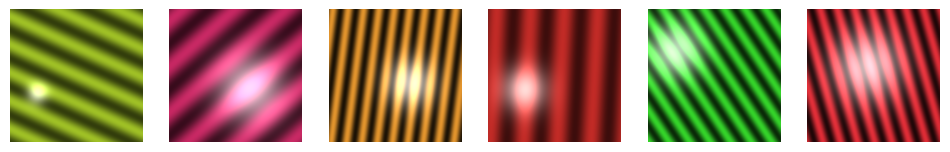

In [14]:
def make_image(orientation, frequency, hue, blob_xy, blob_size, contrast, size=224):
    y, x = np.mgrid[0:size, 0:size] / size
    stripes = 0.5 + 0.5 * contrast * np.sin(2 * np.pi * frequency * (x * np.cos(orientation) + y * np.sin(orientation)))
    image = stripes[..., None] * hsv_to_rgb([hue, 0.8, 1.0])
    blob = np.exp(-((x - blob_xy[0]) ** 2 + (y - blob_xy[1]) ** 2) / (2 * blob_size ** 2))
    return np.clip(image + 0.7 * blob[..., None], 0, 1)


n_images = 200
orientation = rng.uniform(0, np.pi, n_images)
frequency = rng.uniform(2, 12, n_images)
hue = rng.uniform(0, 1, n_images)
blob_xy = rng.uniform(0.2, 0.8, (n_images, 2))
blob_size = rng.uniform(0.05, 0.2, n_images)
contrast = rng.uniform(0.3, 1, n_images)

for i in range(n_images):
    image = make_image(orientation[i], frequency[i], hue[i], blob_xy[i], blob_size[i], contrast[i])
    PILImage.fromarray((image * 255).astype(np.uint8)).save(IMAGE_DIR / f"image_{i:03d}.png")

fig, axes = plt.subplots(1, 6, figsize=(12, 2.2))
for ax, i in zip(axes, range(6)):
    ax.imshow(PILImage.open(IMAGE_DIR / f"image_{i:03d}.png"))
    ax.axis("off")
plt.show()

Now the EEG: 64 electrodes, 100 samples per second from -100 to 800 ms. The planted signal is a mix of the image properties (standardised), only at the back of the head, 100-400 ms after the image. On top come a response shared by all images, and noise. Each participant gets their own noise.

Each `eeg` array has shape (images, electrodes, time points), in volts, like the real data after averaging the repeats.

In [15]:
sfreq = 100
montage = mne.channels.make_standard_montage("biosemi64")
info = mne.create_info(montage.ch_names, sfreq, "eeg")
info.set_montage(montage)
times = np.arange(-0.1, 0.8, 1 / sfreq)
pos = np.array([c["loc"][:3] for c in info["chs"]])

properties = np.column_stack([np.cos(2 * orientation), np.sin(2 * orientation), frequency,
                              np.cos(2 * np.pi * hue), np.sin(2 * np.pi * hue), blob_xy, blob_size, contrast])
properties = (properties - properties.mean(0)) / properties.std(0)

occipital = np.clip(-pos[:, 1] / np.abs(pos[:, 1]).max(), 0, None) ** 2   # strongest at the back of the head
window = (times > 0.1) & (times < 0.4)
envelope = np.zeros(len(times))
envelope[window] = np.hanning(window.sum())
mixing = rng.normal(size=(len(pos), properties.shape[1]))
signal = np.einsum("ik,ck,t->ict", properties, mixing * occipital[:, None], envelope)
erp = 4e-6 * np.exp(-((times - 0.12) / 0.04) ** 2)                      # a response shared by all images

eegs = [1.5e-6 * signal + erp + 3e-6 * rng.normal(size=signal.shape) for _ in range(N_PARTICIPANTS)]
print(len(eegs), "participants:", eegs[0].shape)

3 participants: (200, 64, 90)


The average response of one electrode at the back of the head (Oz), averaged over participants, with the variability across images:

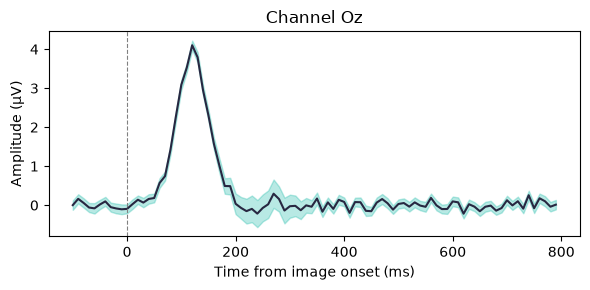

In [16]:
r.plot_erp(np.mean(eegs, axis=0), info, times, "Oz")
plt.tight_layout()
plt.show()

## 2. Create the EEG RDMs

At every time point, each image gives a pattern across the electrodes. The EEG RDM holds, for every pair of images, how different these two patterns are (1 minus the correlation).

`r.eeg_rdms` returns one RDM per time point for each participant, each stored as the numbers above the diagonal of the table.

per participant (time points, image pairs): (90, 19900)


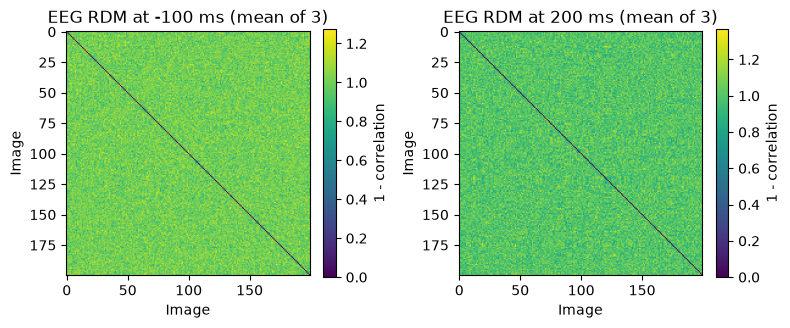

In [17]:
eeg_rdms = [r.eeg_rdms(e) for e in eegs]
print("per participant (time points, image pairs):", eeg_rdms[0].shape)

before = np.argmin(np.abs(times + 0.1))
during = np.argmin(np.abs(times - 0.2))
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, i in zip(axes, (before, during)):
    im = ax.imshow(np.mean([r.rdm(e[:, :, i]) for e in eegs], axis=0), cmap="viridis")
    ax.set(title=f"EEG RDM at {times[i] * 1000:.0f} ms (mean of {len(eegs)})", xlabel="Image", ylabel="Image")
    plt.colorbar(im, ax=ax, label="1 - correlation", fraction=0.046)
plt.tight_layout()
plt.show()

## 3. Load the pretrained model

ResNet-50 from torchvision, pretrained on ImageNet. `weights.transforms()` is the preprocessing the model was trained with (resize, crop, normalise). The first run downloads the weights.

In [18]:
from torchvision.models import resnet50, ResNet50_Weights

weights = ResNet50_Weights.IMAGENET1K_V2
model = resnet50(weights=weights if USE_PRETRAINED else None)
print("last layers:", [n for n, _ in model.named_modules()][-4:])

paths = sorted(IMAGE_DIR.glob("*.png"))                              # same order as the EEG images
images = r.load_images(paths, weights.transforms())
images.shape

last layers: ['layer4.2.bn3', 'layer4.2.relu', 'avgpool', 'fc']


torch.Size([200, 3, 224, 224])

## 4. Create the model RDMs

The activity of the last layer before the classifier (`avgpool`, 2048 numbers per image), then for every pair of images: 1 minus the correlation.

features: (200, 2048)


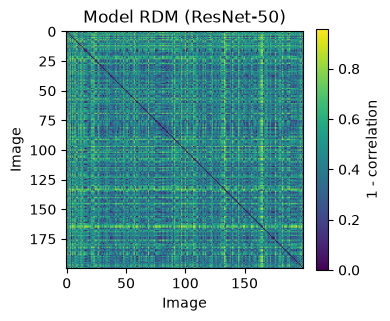

In [19]:
features = r.extract_features(images, model, layer="avgpool")
model_rdm = r.rdm(features)
print("features:", features.shape)

fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(model_rdm, cmap="viridis")
ax.set(title="Model RDM (ResNet-50)", xlabel="Image", ylabel="Image")
plt.colorbar(im, ax=ax, label="1 - correlation", fraction=0.046)
plt.tight_layout()
plt.show()

## 5. RSA: compare the two

For each participant and each time point, the Spearman correlation between the model's table and the brain's table (the numbers above the diagonal). Then the mean and the standard error across participants.

3 participants. Peak RSA 0.147 at 250 ms (planted window: 100-400 ms)


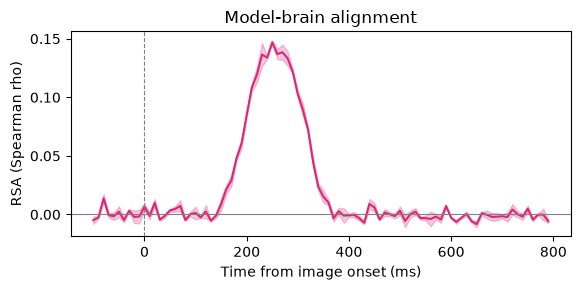

In [20]:
rsa = np.stack([r.spearman(r.upper(model_rdm), x) for x in eeg_rdms])   # (participants, time points)
mean, sem = rsa.mean(0), rsa.std(0) / np.sqrt(len(rsa))
peak = mean.argmax()
print(f"{len(eegs)} participants. Peak RSA {mean[peak]:.3f} at {times[peak] * 1000:.0f} ms (planted window: 100-400 ms)")

ax = r.plot_rsa_timecourse(times, mean)
ax.fill_between(times * 1000, mean - sem, mean + sem, color="#DB2777", alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_DIR / "rsa_timecourse.png", dpi=150)
plt.show()

The two tables side by side at the time of the peak (brain: mean over participants):

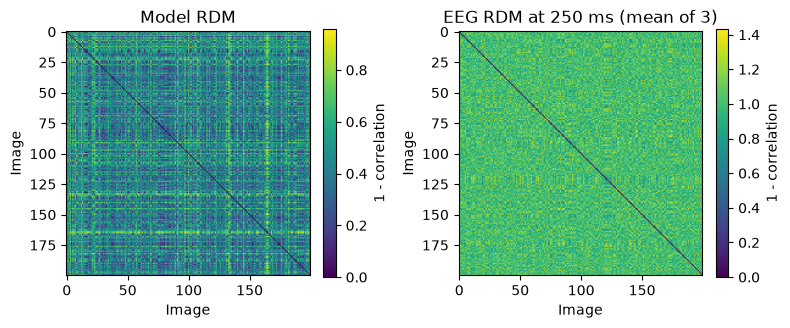

In [21]:
brain_rdm = np.mean([r.rdm(e[:, :, peak]) for e in eegs], axis=0)
r.plot_rdms(model_rdm, brain_rdm, f"EEG RDM at {times[peak] * 1000:.0f} ms (mean of {len(eegs)})")
plt.tight_layout()
plt.savefig(OUT_DIR / "rdms.png", dpi=150)
plt.show()

## 6. Topomaps: where on the head?

The same analysis for every electrode and its 8 nearest neighbours, at every time point, averaged over participants, then played as an animation. (For an .mp4 instead of a .gif, use a path ending in `.mp4`; it needs ffmpeg.)

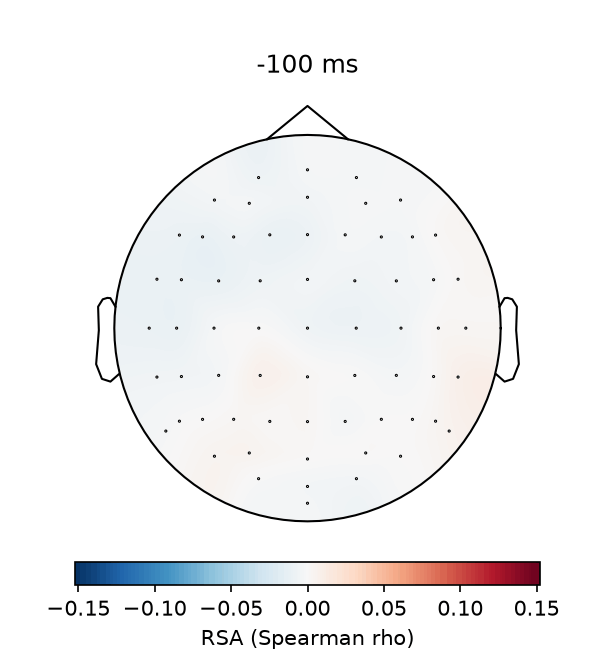

In [22]:
rsa_map = np.stack([r.rsa_searchlight(e, info, model_rdm, n_neighbors=8) for e in eegs]).mean(0)
r.animate_topomap(rsa_map, info, times, OUT_DIR / "rsa_topomap.gif", fps=8, step=2)
Image(filename=OUT_DIR / "rsa_topomap.gif")

### Did it find what we planted?

Nothing before the image appears, the peak lies in the planted window, and the strongest electrodes are at the back of the head.

In [23]:
top = np.argsort(rsa_map[:, peak])[::-1][:5]
print("Top electrodes at the peak:", [info["ch_names"][i] for i in top])

assert 0.1 <= times[peak] <= 0.4, "RSA peak outside the planted window"
assert abs(mean[times < 0].mean()) < 0.02, "RSA before the image should be about 0"
assert pos[top, 1].mean() < 0, "Top electrodes should be at the back of the head"
print("All checks passed")

Top electrodes at the peak: ['O2', 'Oz', 'Iz', 'PO4', 'PO3']
All checks passed
